# Förutsägelse av pallplatser i Formel 1

**Författare:** Felixalfred

I det här projektet undersöker jag om man kan förutsäga vilka förare som tar pallplats (topp 3) i ett Formel 1-lopp, utifrån information som är känd **före** loppet, och vilka faktorer som spelar störst roll.

**Data:** [Formula 1 World Championship (1950-2026)](https://www.kaggle.com/datasets/atharvranjan/formula-1-world-championship-1950-present) från Kaggle.

### Så kör du notebooken
1. Installera paketen: `pip install -r requirements.txt`
2. Öppna notebooken och välj *Run All*. Cellerna är gjorda för att köras uppifrån och ned.

### Innehåll
1. Problem och varför maskininlärning behövs
2. Data och urval
3. Utforskande analys (EDA)
4. Statistiska tester
5. Preprocessing och features
6. Modeller och jämförelse
7. Tolkning av modellen
8. Extra experiment
9. Så fungerar modellen, förklarat utan jargong
10. Slutsats och begränsningar

## Ordlista: Formel 1-begrepp

För den som inte följer Formel 1 förklaras här de begrepp som används i notebooken.

| Begrepp | Förklaring |
|---|---|
| **Lopp (Grand Prix)** | En tävling som körs en gång per tävlingshelg, oftast på söndagen. |
| **Säsong** | Ett år med lopp. I datan har säsongerna mellan 15 och 24 lopp. |
| **Förare** | Den som kör bilen. Varje stall har normalt två förare. |
| **Stall** | Laget som bygger och driver bilarna (t.ex. Ferrari, Mercedes). Stallen tävlar också mot varandra i ett eget mästerskap. |
| **Kval (kvalificering)** | Sessionen före loppet där förarna kör ett snabbt varv var. Resultatet avgör startordningen i loppet. |
| **Grid / startposition** | Startordningen i loppet. Grid 1 står längst fram, grid 2 bredvid osv. |
| **Pole position** | Första startplatsen, som den förare får som kört snabbast i kvalet. Föraren kallas *polesittare*. I den här analysen betyder pole "startade från grid 1", vilket i enstaka fall kan skilja sig från den som körde snabbast, eftersom förare ibland får nedflyttning på griden. |
| **Depåstart** | Start från depån i stället för från griden. I datan visas det oftast som grid 0. |
| **Pallplats (podium)** | Att sluta på plats 1, 2 eller 3 i loppet. De tre första står på prispallen. Det är det jag försöker förutsäga. |
| **Målposition** | Placeringen i mål. Saknas för förare som inte blev klassificerade. |
| **Att bryta loppet (DNF)** | Att inte ta sig i mål, till exempel på grund av olycka eller motorfel. Sådana förare saknar målposition i datan. |
| **Hybrid-eran** | Perioden från 2014, då bilarna började använda turboladdade hybridmotorer. Min analys börjar där. |
| **Poäng** | Förarna och stallen får poäng efter placering i loppet. |

## 1. Problem och varför maskininlärning behövs

**Frågeställning:** Kan man förutsäga om en förare tar pallplats (plats 1-3) i ett lopp, utifrån sådant som är känt före start, till exempel startposition, kvalresultat samt förarens och stallets form? Vilka faktorer väger tyngst?

**Typ av problem:** Binär klassificering. Målvariabeln är *pallplats* (ja/nej). Klasserna är obalanserade, eftersom bara tre av ungefär tjugo förare hamnar på pallen i varje lopp (ca 15 %).

**Varför räcker det inte med en enkel regel?** En vanlig tumregel är "den som står på pole vinner". Men hur mycket startpositionen betyder varierar mellan banor (det är svårt att köra om på Monaco), mellan stall (en snabb bil kan köra upp från mitten av fältet) och mellan år (regler och bilar kan förändras). Flera faktorer samverkar dessutom. Maskininlärning kan väga ihop många signaler samtidigt och lära sig dessa samband från historiska lopp. Jag jämför därför modellerna mot just tumregeln, för att visa om maskininlärning faktiskt tillför något.

## 2. Data och urval

Datasetet består av flera tabeller (CSV-filer) som hänger ihop via id-kolumner, till exempel `raceId` och `driverId`. Jag använder dessa:

| Tabell | Innehåll |
|---|---|
| `results` | Resultat per förare och lopp: startposition (`grid`), målposition, poäng, status |
| `races` | Ett lopp per rad: säsong, rundenummer, bana, datum |
| `qualifying` | Kvalresultat per förare och lopp, inklusive tider i Q1, Q2 och Q3 |
| `drivers` | Information om förarna |
| `constructors` | Information om stallen |
| `circuits` | Information om banorna, bland annat koordinater |
| `status` | Förklaring av hur varje förare avslutade loppet (t.ex. i mål, olycka, motorfel) |

Datasetet innehåller också tabellerna `lap_times` och `pit_stops`, men de behövs inte för den här frågeställningen och används därför inte.

### 2.1 Importer och sökväg till datan

Först importerar jag de bibliotek jag behöver:
- `pandas` för att läsa in och hantera tabeller
- `Path` från standardbiblioteket för att hantera filsökvägar på ett sätt som fungerar på både Windows, Mac och Linux

Notebooken ligger i mappen `notebooks/` och datan i `data_raw/`. Därför går sökvägen först upp en nivå (`..`) och sedan in i `data_raw`.

In [1]:
import pandas as pd
from pathlib import Path

# Mappen med rådatan, sett från notebookens plats
DATA = Path("../data_raw")

### 2.2 Funktion för att läsa in en tabell

Jag skriver en liten funktion så att jag slipper upprepa samma rad för varje tabell.

Viktigt här är `na_values="\\N"`. I datasetet står tecknen `\N` där ett värde saknas. Om jag inte berättar det för pandas tolkas `\N` som vanlig text, och då blir hela kolumner (t.ex. `position`) textkolumner i stället för tal. Med inställningen omvandlas `\N` till riktiga saknade värden (`NaN`), som jag kan hantera på ett kontrollerat sätt.

In [2]:
def load(name):
    """Läser in en CSV-fil från data_raw och returnerar den som en pandas-tabell (DataFrame)."""
    return pd.read_csv(DATA / f"{name}.csv", na_values="\\N")

### 2.3 Läs in tabellerna

Varje tabell sparas i en egen variabel med samma namn som filen.

In [ ]:
results       = load("results")
races         = load("races")
qualifying    = load("qualifying")
drivers       = load("drivers")
constructors  = load("constructors")
circuits      = load("circuits")
status        = load("status")

### 2.4 Kontrollera storleken

Det första jag gör efter inläsning är att kontrollera att tabellerna har rimlig storlek. `shape` visar *(antal rader, antal kolumner)*. Det är en enkel kontroll av att inläsningen gått rätt till och att inga filer är tomma eller trasiga.

In [4]:
tabeller = {
    "results": results,
    "races": races,
    "qualifying": qualifying,
    "drivers": drivers,
    "constructors": constructors,
    "circuits": circuits,
    "status": status,
}

for namn, tabell in tabeller.items():
    print(f"{namn:<13} {tabell.shape[0]:>6} rader, {tabell.shape[1]:>2} kolumner")

results        27568 rader, 18 kolumner
races           1164 rader, 18 kolumner
qualifying     11298 rader,  9 kolumner
drivers          879 rader,  9 kolumner
constructors     214 rader,  5 kolumner
circuits          78 rader,  9 kolumner
status           141 rader,  2 kolumner


### 2.5 Titta på de första raderna

`head()` visar de fem första raderna. Det ger en känsla för hur datan ser ut. Här ser jag bland annat att varje rad i `results` är en förare i ett lopp, och att tabellen hänvisar till andra tabeller via id-kolumner (`raceId`, `driverId`, `constructorId`).

In [5]:
results.head()

,resultId,raceId,driverId,constructorId,number,grid,position,positionText,positionOrder,points,laps,time,milliseconds,fastestLap,rank,fastestLapTime,fastestLapSpeed,statusId
0,1,18,1,1,22.0,1,1.0,1,1,10.0,58,1:34:50.616,5690616.0,39.0,2.0,1:27.452,218.300,1
1,2,18,2,2,3.0,5,2.0,2,2,8.0,58,+5.478,5696094.0,41.0,3.0,1:27.739,217.586,1
2,3,18,3,3,7.0,7,3.0,3,3,6.0,58,+8.163,5698779.0,41.0,5.0,1:28.090,216.719,1
3,4,18,4,4,5.0,11,4.0,4,4,5.0,58,+17.181,5707797.0,58.0,7.0,1:28.603,215.464,1
4,5,18,5,1,23.0,3,5.0,5,5,4.0,58,+18.014,5708630.0,43.0,1.0,1:27.418,218.385,1


### 2.6 Datatyper och saknade värden

Jag kontrollerar att kolumnerna har rätt datatyp (tal ska vara tal) och hur många värden som saknas. `dtypes` visar datatypen per kolumn och `isna().sum()` räknar saknade värden.

Saknade värden är inte alltid fel. En förare som bröt loppet har till exempel ingen målposition (`position`). Det betyder att tabellen innehåller information i sig, och det tar jag hänsyn till när jag bygger målvariabeln.

In [6]:
results.dtypes

resultId             int64
raceId               int64
driverId             int64
constructorId        int64
number             float64
grid                 int64
position           float64
positionText           str
positionOrder        int64
points             float64
laps                 int64
time                   str
milliseconds       float64
fastestLap         float64
rank               float64
fastestLapTime         str
fastestLapSpeed    float64
statusId             int64
dtype: object

In [7]:
results.isna().sum()

resultId               0
raceId                 0
driverId               0
constructorId          0
number                 6
grid                   0
position           11074
positionText           0
positionOrder          0
points                 0
laps                   0
time               19212
milliseconds       19200
fastestLap         18542
rank               18284
fastestLapTime     18542
fastestLapSpeed    19316
statusId               0
dtype: int64

### 2.7 Vilka säsonger finns i datan, och varför väljer jag 2014-2026?

Datasetet täcker 1950 till 2026, men jag avgränsar analysen till **2014-2026**. Skälen är:

- **Jämförbara regler och bilar.** Säsongen 2014 infördes hybridtekniken med turboladdade V6-motorer, och sedan dess är bilarna och förutsättningarna rimligt jämförbara. Ett lopp från 1970-talet och ett från 2020-talet skiljer sig så mycket i teknik, säkerhet och tillförlitlighet att en modell som lär sig av båda lätt blir svårtolkad. Det är till exempel mycket vanligare att bilar går sönder i äldre lopp.
- **Mer komplett data.** Tabellen `pit_stops` finns bara från 2011, och det gäller flera andra tabeller också. Att börja 2014 ger fullständiga uppgifter för alla de tabeller jag vill kunna använda.
- **Tillräckligt många observationer.** Perioden ger 13 säsonger och drygt 5 400 rader i `results` (en per förare och lopp), vilket räcker för att träna och jämföra flera modeller.
- **Aktuell relevans.** Jag vill kunna testa modellen på de senaste loppen, vilket ligger närmast hur sporten fungerar nu.

**Begränsningar:** Perioden innehåller också regelförändringar, bland annat 2022 (nya aerodynamiska regler) och 2026 (nya tekniska regler, och två nya stall, Audi och Cadillac). Säsongen 2026 är dessutom inte komplett i datan. Jag hanterar det genom att dela upp datan i tid, så att modellen tränas på äldre säsonger och testas på de senaste, och jag tar upp effekten i diskussionen.

Först kollar jag vilka år som finns och hur många lopp varje säsong har.

In [10]:
# Första säsongen som tas med i analysen (hybrid-eran börjar 2014)
FIRST_SEASON = 2014

print("Första säsong i datan:", races["year"].min())
print("Senaste säsong i datan:", races["year"].max())

# Antal lopp per säsong i den period jag analyserar
races[races["year"] >= FIRST_SEASON].groupby("year").size()

Första säsong i datan: 1950
Senaste säsong i datan: 2026


year
2014    19
2015    19
2016    21
2017    20
2018    21
2019    21
2020    17
2021    22
2022    22
2023    22
2024    24
2025    24
2026    15
dtype: int64

### 2.8 Slå ihop tabellerna till en analystabell

Datan ligger i flera tabeller, men för analysen vill jag ha **en tabell med en rad per förare och lopp**. Jag utgår från `results` och lägger till information om loppet (säsong, bana, namn), föraren och stallet. Tabellerna kopplas ihop via id-kolumnerna (`raceId`, `driverId`, `constructorId`) med `merge`.

Två detaljer som gör sammanslagningen säker:
- `how="left"` behåller alla rader från `results`, även om en matchning skulle saknas.
- `validate="many_to_one"` kontrollerar att varje resultatrad matchar **exakt en** rad i den andra tabellen. Om id-kolumnerna skulle innehålla dubbletter hade pandas gett ett felmeddelande i stället för att tyst skapa extra rader.

Jag kontrollerar också att antalet rader är oförändrat efter sammanslagningen. Kolumnerna `points` och `statusId` tar jag med för den utforskande analysen, men de beskriver resultatet av loppet och är därför **inte** tillåtna som features i modellen. Det skulle vara dataläckage.

In [11]:
# Välj ut de kolumner jag behöver och döp om de som har samma namn i olika tabeller
races_small = races[["raceId", "year", "round", "circuitId", "name", "date"]].rename(columns={"name": "race_name"})
drivers_small = drivers[["driverId", "forename", "surname"]]
constructors_small = constructors[["constructorId", "name"]].rename(columns={"name": "constructor_name"})

# Slå ihop: varje resultatrad får info om lopp, förare och stall
df = (
    results
    .merge(races_small, on="raceId", how="left", validate="many_to_one")
    .merge(drivers_small, on="driverId", how="left", validate="many_to_one")
    .merge(constructors_small, on="constructorId", how="left", validate="many_to_one")
)

# Förarens fulla namn i en kolumn
df["driver"] = df["forename"] + " " + df["surname"]

# Behåll bara de kolumner jag behöver
df = df[["raceId", "year", "round", "race_name", "date", "circuitId", "driverId", "driver",
         "constructorId", "constructor_name", "grid", "position", "positionOrder", "points", "statusId"]]

# Kontroll: samma antal rader som i results?
print("Samma antal rader som results:", len(df) == len(results), "-", len(df), "rader")

Samma antal rader som results: True - 27568 rader


### 2.9 Avgränsa till den valda perioden

Nu filtrerar jag bort säsongerna före `FIRST_SEASON` (2014), enligt motiveringen i avsnitt 2.7. `.copy()` gör en egen kopia av den filtrerade tabellen, så att jag senare kan lägga till kolumner utan varningar från pandas.

In [12]:
df = df[df["year"] >= FIRST_SEASON].copy()

print("Rader:", len(df))
print("Säsonger:", df["year"].min(), "-", df["year"].max())
print("Antal lopp:", df["raceId"].nunique())

Rader: 5435
Säsonger: 2014 - 2026
Antal lopp: 267


### 2.10 Skapa målvariabeln: pallplats

Det jag vill förutsäga är om en förare **tar pallplats**, det vill säga slutar på plats 1, 2 eller 3. Jag skapar därför kolumnen `podium` med värdet 1 om `position` är 3 eller lägre, och annars 0.

Förare som inte kom i mål saknar värde i `position` (`NaN`). I en jämförelse som `NaN <= 3` blir resultatet falskt, så de får automatiskt `podium = 0`. Det är rimligt, eftersom en förare som bröt loppet inte kan ha tagit pallplats.

Som kontroll räknar jag antalet pallplatser per lopp. Det ska vara exakt tre i varje lopp. Om något lopp avviker tyder det på ett fel i datan eller i min definition.

In [13]:
# 1 = pallplats (plats 1-3), 0 = ingen pallplats (inklusive de som bröt loppet)
df["podium"] = (df["position"] <= 3).astype(int)

# Kontroll: antal pallplatser per lopp ska vara exakt 3
df.groupby("raceId")["podium"].sum().value_counts()

podium
3    267
Name: count, dtype: int64

### 2.11 Hur ser fördelningen av målvariabeln ut?

Innan jag modellerar vill jag veta hur vanligt det är med pallplats. Det avgör både hur jag ska utvärdera modellerna och vad en enkel gissning skulle ge. Eftersom bara tre av ungefär tjugo förare hamnar på pallen i varje lopp är klasserna **obalanserade**: en modell som alltid gissar "ingen pallplats" skulle ha ungefär 85 % rätt utan att ha lärt sig något. Därför räcker det inte att titta på accuracy (andelen rätt), utan jag använder mått som tar hänsyn till obalansen (t.ex. ROC-AUC, precision och recall).

Jag kollar också hur många förare som startade från grid-position 0. Det betyder oftast start från depån, och de behöver hanteras särskilt i preprocessingen senare.

In [14]:
print("Antal per klass:")
print(df["podium"].value_counts())
print()
print(f"Andel pallplatser: {df['podium'].mean():.1%}")
print()
print("Antal starter med grid = 0:", (df["grid"] == 0).sum())

Antal per klass:
podium
0    4634
1     801
Name: count, dtype: int64

Andel pallplatser: 14.7%

Antal starter med grid = 0: 79


## 3. Utforskande analys (EDA)

Innan jag bygger några modeller undersöker jag datan för att förstå vad den innehåller och vilka samband som finns. Jag ställer fyra frågor som är kopplade till frågeställningen:

1. Hur mycket betyder startpositionen för chansen till pallplats?
2. Hur ofta vinner den som står på pole, och är det stabilt över åren?
3. Hur ofta når förare inte målet, och har det ändrats?
4. Hur har stallens styrka förändrats över tid?

In [15]:
import matplotlib.pyplot as plt
import seaborn as sns

# Ljus bakgrund med rutnät för alla diagram
sns.set_theme(style="whitegrid")

### 3.1 Startposition och chans till pallplats

Först undersöker jag sambandet mellan startposition (`grid`) och pallplats. Jag beräknar andelen förare som tog pallplats för varje startposition. Positionerna 1-20 tas med, eftersom grid 0 (start från depån) och grid 21-22 (finns bara vissa säsonger) har för få observationer för att vara meningsfulla.

grid
1    80.9
2    71.7
3    54.3
4    35.6
5    17.2
Name: podium, dtype: float64


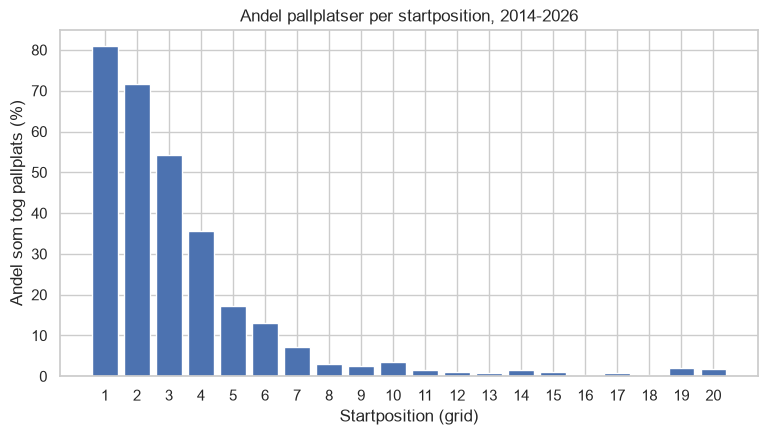

In [16]:
# Andel pallplatser (%) per startposition
podium_by_grid = (
    df[df["grid"].between(1, 20)]
    .groupby("grid")["podium"]
    .mean() * 100
)
print(podium_by_grid.head(5).round(1))

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.bar(podium_by_grid.index, podium_by_grid.values, color="#4C72B0")
ax.set_xlabel("Startposition (grid)")
ax.set_ylabel("Andel som tog pallplats (%)")
ax.set_title("Andel pallplatser per startposition, 2014-2026")
ax.set_xticks(range(1, 21))
plt.show()

**Tolkning:** Startpositionen har ett mycket starkt samband med pallplats. Från pole tog 80,9 % pallplats, från plats 2 71,7 %, från plats 3 54,3 % och från plats 4 35,6 %. Efter plats 7 är andelen under 10 %, och från plats 8 och bakåt nästan noll. Sambandet är alltså starkt men inte deterministiskt: nästan var femte polesittare (19 %) tog **inte** pallplats. Det visar att startposition är en viktig feature, men att den inte räcker själv.

### 3.2 Hur ofta vinner den som startar från pole?

Tumregeln "den som står på pole vinner" är den enklaste prognosen jag kan jämföra mot. Här undersöker jag hur bra den är, och om den fungerar lika bra varje säsong. Med pole menar jag här grid-position 1. Den kan skilja sig från den som faktiskt tog bästa kvaltid, eftersom förare ibland får nedflyttning på startgriden.

Antal polepositioner: 267
Andel som vann: 54.3%
Andel som tog pallplats: 80.9%


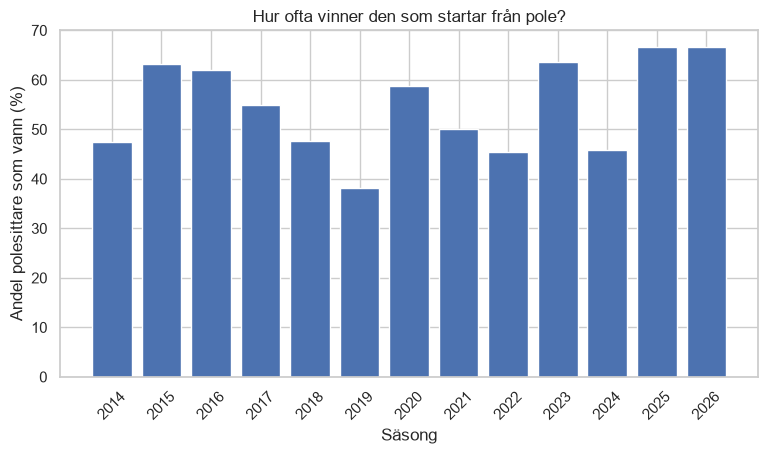

In [17]:
# Polesittare = förare som startade från grid-position 1
pole = df[df["grid"] == 1].copy()
pole["won"] = (pole["position"] == 1)

print(f"Antal polepositioner: {len(pole)}")
print(f"Andel som vann: {pole['won'].mean():.1%}")
print(f"Andel som tog pallplats: {pole['podium'].mean():.1%}")

# Andel segrar från pole per säsong
pole_win_by_year = pole.groupby("year")["won"].mean() * 100

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.bar(pole_win_by_year.index, pole_win_by_year.values, color="#4C72B0")
ax.set_xlabel("Säsong")
ax.set_ylabel("Andel polesittare som vann (%)")
ax.set_title("Hur ofta vinner den som startar från pole?")
ax.set_xticks(pole_win_by_year.index)
ax.tick_params(axis="x", rotation=45)
plt.show()

**Tolkning:** Av 267 polepositioner ledde 54,3 % till seger och 80,9 % till pallplats. Tumregeln "pole = vinst" stämmer alltså bara ungefär varannan gång, och nästan var femte polesittare tar inte ens pallplats. Andelen segrar varierar mellan säsongerna (från 38 % 2019 till 67 % 2025 och 2026), men eftersom varje säsong bara har 15-24 polepositioner är det svårt att skilja verklig variation från slump. Jag testar det statistiskt i nästa kapitel. Observera att 2026 är en ofullständig säsong (15 lopp).

### 3.3 Hur ofta når förare inte målet?

Förare som inte blev klassificerade saknar målposition (`position` är tom). Det omfattar förare som bröt loppet, blev diskvalificerade eller inte startade. De kan aldrig ta pallplats, så en hög andel ger mer slump i resultatet. Jag undersöker hur andelen har förändrats per säsong.

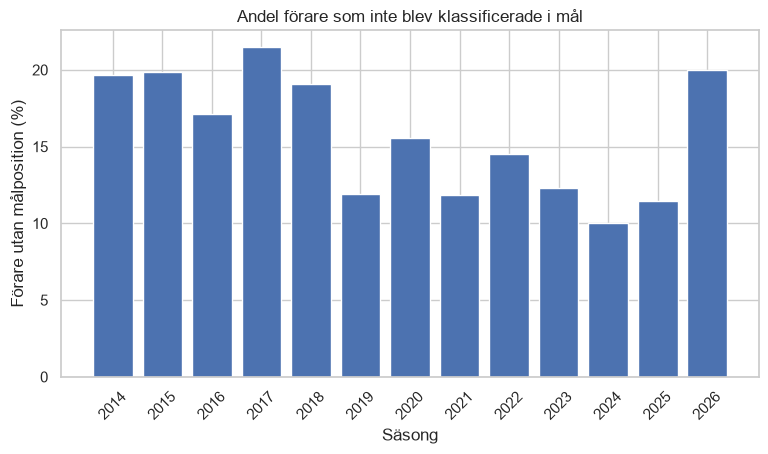

In [18]:
# Andel förare utan målposition (%) per säsong
not_classified_by_year = df["position"].isna().groupby(df["year"]).mean() * 100

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.bar(not_classified_by_year.index, not_classified_by_year.values, color="#4C72B0")
ax.set_xlabel("Säsong")
ax.set_ylabel("Förare utan målposition (%)")
ax.set_title("Andel förare som inte blev klassificerade i mål")
ax.set_xticks(not_classified_by_year.index)
ax.tick_params(axis="x", rotation=45)
plt.show()

**Tolkning:** Mellan 10 % och 21,5 % av förarna blev inte klassificerade i ett lopp, beroende på säsong. Det var högst 2017 (21,5 %) och lägst 2024 (10,0 %). Det betyder att tillförlitlighet och olyckor tar bort en betydande del av förarna varje lopp, och det är en slumpfaktor som ingen modell kan förutsäga utifrån informationen före start. Det sätter en gräns för hur bra modellen kan bli.

### 3.4 Stallens styrka över tid

I Formel 1 spelar bilen minst lika stor roll som föraren. Jag undersöker därför hur pallplatserna har fördelats mellan stallen. Värmekartan visar antalet pallplatser per säsong för de sex stall som tagit flest pallplatser under perioden. Observera att ett stall kan byta namn (t.ex. Force India, Racing Point och Aston Martin), och att datasetet då ser dem som olika stall.

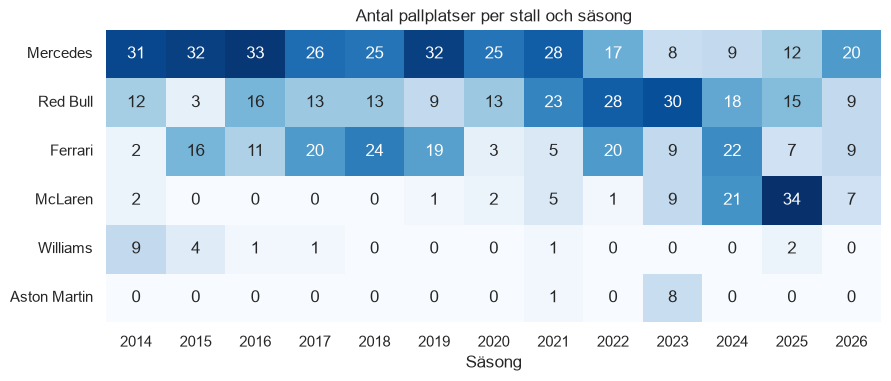

In [20]:
# De sex stall som tagit flest pallplatser under perioden
podiums_by_team = (
    df[df["podium"] == 1]
    .groupby("constructor_name")
    .size()
    .sort_values(ascending=False)
)
top_teams = podiums_by_team.head(6).index

# Tabell: antal pallplatser per stall (rader) och säsong (kolumner)
team_season = (
    df[(df["podium"] == 1) & (df["constructor_name"].isin(top_teams))]
    .pivot_table(index="constructor_name", columns="year", values="podium",
                 aggfunc="sum", fill_value=0)
    .reindex(top_teams)
)

fig, ax = plt.subplots(figsize=(10, 3.8))
sns.heatmap(team_season, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax)
ax.set_xlabel("Säsong")
ax.set_ylabel("")
ax.set_title("Antal pallplatser per stall och säsong")
plt.show()

Värmekartan ovan visar mängden pallplatser, men det är svårt att följa ett enskilt stalls utveckling. Linjediagrammet nedan visar de fyra stallen med flest pallplatser. Här har jag använt stallens färger, eftersom färgen i det här diagrammet säger *vilket stall* linjen tillhör. Färgerna är justerade så att de syns tydligt mot den vita bakgrunden. Namnen står direkt vid linjerna, så att diagrammet går att tolka även utan färger. Säsongen 2026 är utelämnad eftersom den är ofullständig.

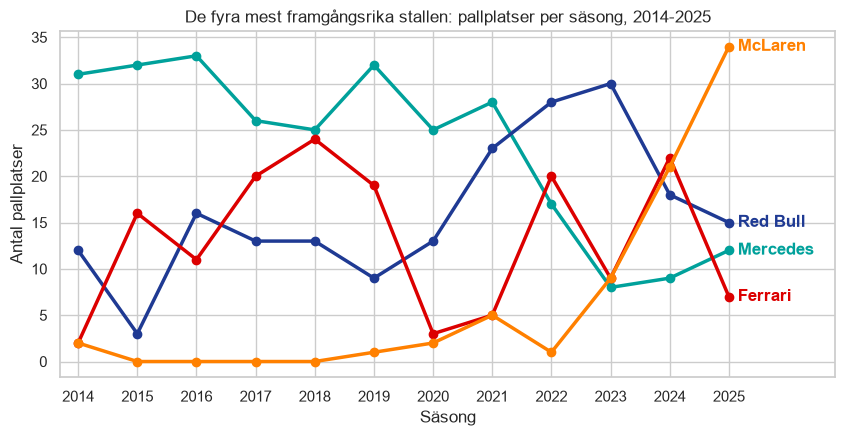

In [21]:
# Stallfärger (justerade för att synas tydligt mot vit bakgrund)
team_colors = {
    "Mercedes": "#00A19B",
    "Red Bull": "#1F3A93",
    "Ferrari": "#DC0000",
    "McLaren": "#FF8000",
}

# 2026 är en ofullständig säsong och lämnas utanför diagrammet
full_seasons = team_season.loc[:, team_season.columns < 2026]

fig, ax = plt.subplots(figsize=(10, 4.5))
for team, color in team_colors.items():
    ax.plot(full_seasons.columns, full_seasons.loc[team], marker="o", color=color, linewidth=2.5)
    # Namnet skrivs direkt vid linjens slut, så att ingen teckenförklaring behövs
    ax.text(full_seasons.columns[-1] + 0.15, full_seasons.loc[team].iloc[-1], team,
            color=color, va="center", fontweight="bold")

ax.set_xlabel("Säsong")
ax.set_ylabel("Antal pallplatser")
ax.set_title("De fyra mest framgångsrika stallen: pallplatser per säsong, 2014-2025")
ax.set_xticks(full_seasons.columns)
ax.set_xlim(full_seasons.columns[0] - 0.3, full_seasons.columns[-1] + 1.8)
plt.show()

**Tolkning:** Pallplatserna är starkt koncentrerade till ett fåtal stall, och vilket stall som dominerar skiftar över tid. Mercedes tog 25-33 pallplatser per säsong 2014-2021, Red Bull dominerade 2022-2023 (28 och 30 pallplatser) och McLaren 2024-2025 (21 och 34). Under en dominerande period är chansen till pallplats mycket högre för ett stalls förare än för andra, oavsett startposition. Det motiverar att jag i modellen tar med stallets **senaste form** och inte bara en fast stallidentitet, och att jag delar upp datan i tid. Namnbyten på stall (t.ex. Aston Martin som tidigare hette Force India och Racing Point) måste jag hantera när jag bygger features.

## 4. Statistiska tester

I EDA såg jag flera samband. Här undersöker jag med statistiska tester om de är statistiskt säkerställda, eller om de lika gärna kan bero på slumpen. För varje test anger jag en nollhypotes (H0), motiverar valet av test och kontrollerar testets antaganden. Jag använder signifikansnivån 5 % (p < 0.05 betyder att jag förkastar H0).

Eftersom datasetet är stort (drygt 5 000 observationer) blir p-värdena ofta extremt små även för små skillnader. Jag redovisar därför också **effektstorlek**, som säger hur stort sambandet är, inte bara om det finns.

In [22]:
import numpy as np
from scipy import stats

ALPHA = 0.05  # signifikansnivå

def fmt_p(p):
    """Formaterar ett p-värde så att mycket små värden skrivs som p < 0.001."""
    return "p < 0.001" if p < 0.001 else f"p = {p:.3f}"

### 4.1 Hänger start på grid 1–3 ihop med pallplats?

- **H0:** Att starta på grid 1-3 och att ta pallplats är oberoende av varandra.
- **H1:** De hänger ihop.
- **Test:** Chi-två-test för oberoende, eftersom båda variablerna är kategoriska (ja/nej) och kan sammanfattas i en 2x2-tabell.
- **Antagande:** Det förväntade antalet i varje ruta ska vara minst 5. Observationerna förutsätts vara oberoende av varandra, vilket inte stämmer helt.
- **Effektstorlek:** phi (0 = inget samband, 1 = perfekt samband) och oddskvot.

In [28]:
# Rader: startade på främre raden (grid 1-3)? Kolumner: tog pallplats?
top3_start = df["grid"].between(1, 3).rename("top3_start")
table = pd.crosstab(top3_start, df["podium"])
print(table)
print()
print((table.div(table.sum(axis=1), axis=0) * 100).round(1))

chi2, p, dof, expected = stats.chi2_contingency(table)
n = table.values.sum()
phi = np.sqrt(chi2 / n)
odds_ratio = (table.loc[True, 1] / table.loc[True, 0]) / (table.loc[False, 1] / table.loc[False, 0])

print(f"\nchi2 = {chi2:.1f}, frihetsgrader = {dof}, {fmt_p(p)}")
print(f"Effektstorlek (phi): {phi:.2f}")
print(f"Oddskvot: {odds_ratio:.1f}")
print(f"Minsta förväntade antal i en ruta: {expected.min():.1f} (ska vara minst 5)")

podium         0    1
top3_start           
False       4386  250
True         248  551

podium         0     1
top3_start            
False       94.6   5.4
True        31.0  69.0

chi2 = 2186.7, frihetsgrader = 1, p < 0.001
Effektstorlek (phi): 0.63
Oddskvot: 39.0
Minsta förväntade antal i en ruta: 117.8 (ska vara minst 5)


**Tolkning:** Av förarna som startade topp 3 tog 69,0 % pallplats, jämfört med 5,4 % av övriga. Chi-två-testet ger χ²(1) = 2186,7 och p < 0.001, så jag förkastar H0: främre raden och pallplats hänger ihop. Effektstorleken är stor (phi = 0,63) och oddsen för pallplats är ungefär 39 gånger högre från främre raden. Antagandet om förväntade antal är uppfyllt (minst 117,8 i varje ruta).

### 4.2 Startar förare som tar pallplats längre fram?

- **Fråga:** Startar förare som tar pallplats längre fram än de som inte gör det?
- **H0:** Det är ingen skillnad i startposition mellan grupperna.
- **H1:** Det är skillnad.
- **Test:** Mann-Whitney U. Jag väljer det i stället för ett t-test, eftersom startposition är en rangordning och inte normalfördelad (se Shapiro-Wilk-testet nedan).
- **Effektstorlek:** Sannolikheten att en förare med pallplats startat före en förare utan pallplats. Den kan också tolkas som ROC-AUC om man bara använder startposition som prognos, och blir en jämförelsepunkt för modellerna senare.

In [24]:
starters = df[df["grid"] >= 1]
podium_grid = starters.loc[starters["podium"] == 1, "grid"]
other_grid = starters.loc[starters["podium"] == 0, "grid"]

print("Median startposition, pallplats:", podium_grid.median())
print("Median startposition, ej pallplats:", other_grid.median())

# Är startposition normalfördelad? (Shapiro-Wilk på ett slumpmässigt urval om 500)
print(stats.shapiro(starters["grid"].sample(500, random_state=42)))

u, p = stats.mannwhitneyu(podium_grid, other_grid, alternative="two-sided")
auc = 1 - u / (len(podium_grid) * len(other_grid))
print(f"U = {u:.0f}, {fmt_p(p)}")
print(f"Sannolikhet att en pallplatsförare startat före en förare utan pallplats: {auc:.1%}")

Median startposition, pallplats: 2.0
Median startposition, ej pallplats: 12.0
ShapiroResult(statistic=np.float64(0.9428981414874922), pvalue=np.float64(6.050367786705743e-13))
U = 289422, p < 0.001
Sannolikhet att en pallplatsförare startat före en förare utan pallplats: 92.1%


**Tolkning:** Mediansstartpositionen är 2 för förare som tog pallplats och 12 för övriga. Shapiro-Wilk förkastar normalfördelning (p < 0.001), vilket motiverar Mann-Whitney U. Testet ger p < 0.001, så jag förkastar H0: startpositionen skiljer sig tydligt åt. I 92,1 % av jämförelserna hade pallplatsföraren startat före den andra föraren. Det betyder att **startposition ensam redan är en mycket stark prognos** (motsvarande ROC-AUC ≈ 0,92), och att mina modeller måste prestera bättre än så för att tillföra något.

### 4.3 Hur starkt hänger startposition och målposition ihop?

- **H0:** Det finns ingen monoton korrelation mellan startposition och målposition (ρ = 0).
- **H1:** Det finns en korrelation.
- **Test:** Spearmans rangkorrelation. Den passar för rangordnade variabler och mäter om högre startnummer tenderar att ge högre slutnummer, utan att kräva ett linjärt samband eller normalfördelning.
- Endast förare som startade från grid 1 eller längre bak och blev klassificerade i mål ingår (annars saknas målposition).

In [25]:
classified = df[(df["grid"] >= 1) & df["position"].notna()]
rho, p = stats.spearmanr(classified["grid"], classified["position"])
print(f"Spearman rho = {rho:.2f}, {fmt_p(p)}, n = {len(classified)}")

Spearman rho = 0.76, p < 0.001, n = 4533


**Tolkning:** Spearmans ρ är 0,76 (p < 0.001, n = 4 533), så jag förkastar H0. Det finns en stark positiv korrelation: den som startar långt bak slutar oftast också långt bak. Sambandet är starkt men inte perfekt, eftersom förare ibland kör upp eller tappar många platser. Det lämnar utrymme för att andra faktorer, som stallets styrka, förklarar något mer.

### 4.4 Varierar andelen segrar från pole mellan säsongerna?

I 3.2 såg det ut som att andelen polesittare som vann varierade mycket mellan säsongerna (38-67 %). Jag testar om skillnaden är statistiskt säkerställd.

- **H0:** Andelen polesittare som vinner är lika stor i alla säsonger.
- **H1:** Andelen skiljer sig mellan minst två säsonger.
- **Test:** Chi-två-test på en tabell med säsong (13 rader) och vann/vann inte (2 kolumner).
- **Antagande:** Förväntat antal minst 5 i varje ruta. Jag redovisar också ett 95 %-igt konfidensintervall för den totala andelen.

In [26]:
# pole skapades i avsnitt 3.2 (förare som startade från grid 1, med kolumnen "won")
table = pd.crosstab(pole["year"], pole["won"])
chi2, p, dof, expected = stats.chi2_contingency(table)
print(f"chi2 = {chi2:.2f}, frihetsgrader = {dof}, {fmt_p(p)}")
print(f"Minsta förväntade antal i en ruta: {expected.min():.1f}")

ci = stats.binomtest(int(pole["won"].sum()), len(pole)).proportion_ci(method="wilson")
print(f"95 % konfidensintervall för andelen segrar från pole: {ci.low:.1%} - {ci.high:.1%}")

chi2 = 8.93, frihetsgrader = 12, p = 0.709
Minsta förväntade antal i en ruta: 6.9
95 % konfidensintervall för andelen segrar från pole: 48.3% - 60.2%


**Tolkning:** Testet ger χ²(12) = 8,93 och p = 0,709, så jag **kan inte förkasta H0**. Skillnaderna mellan säsongerna är förenliga med slumpen, vilket är rimligt eftersom varje säsong bara har 15-24 polepositioner. Det betyder inte att säsongerna *är* lika, bara att datan inte räcker för att visa en skillnad. Minsta förväntade antal i en ruta är 6,9, vilket uppfyller kravet på minst 5, så chi-två-testet är lämpligt. Den totala andelen segrar från pole är 54,3 % med ett 95 %-igt konfidensintervall på 48,3-60,2 %. Det är ett exempel på att en iakttagelse i ett diagram inte alltid håller för ett statistiskt test.

### 4.5 Sammanfattning: vad betyder testerna för modelleringen?

| Test | Fråga | Resultat | Konsekvens |
|---|---|---|---|
| Chi-två (4.1) | Topp 3 på griden och pallplats | Stort samband (phi 0,63, p < 0.001) | Startposition är en nyckelfeature |
| Mann-Whitney U (4.2) | Startposition, pallplats mot övriga | p < 0.001, ROC-AUC ≈ 0,92 | Startposition ensam är en stark baslinje som modellerna måste slå |
| Spearman (4.3) | Start- och målposition | ρ = 0,76 (p < 0.001) | Starkt men inte perfekt samband, det finns plats för fler features |
| Chi-två (4.4) | Pole-vinst mellan säsonger | p = 0,709 | Ingen säkerställd skillnad mellan säsonger |

**Begränsningar:** Testerna förutsätter oberoende observationer, men förare i samma lopp påverkas av samma förhållanden (väder, olyckor) och samma förare förekommer många gånger. P-värdena är därför troligen något för optimistiska. Eftersom p-värdena i 4.1-4.3 är extremt små påverkas slutsatserna inte av att jag gör flera tester, men effektstorlekarna är viktigare att fokusera på än p-värdena.